# étapes : 
1. tf du signal

2. faire spectrogramme 

3. decomposer le spectrogramme 

4. tf inverse

# But : 
analyser un signal sonore
séparer différentes sources

Problème : quand on passe en foruier on perd toutes les infos temporelles 
Solution : spectogramme  (t / freq)
spectrogramme ~= Fourier sur une fenêtre glissante pour garder la dimension temps


In [3]:
from scipy.io.wavfile import read
import numpy as np
from numpy.fft import fft, fftshift, ifft, fftfreq
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy
import math


44100
154028


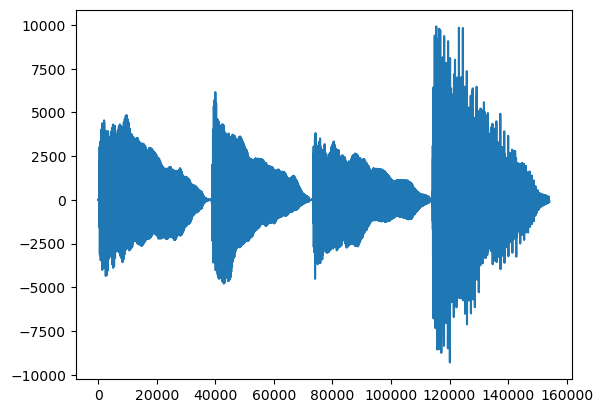

In [4]:
rate, x = read("Fichiers_sonores/piano_mix.wav")
print(rate)
t = np.linspace(0, x.size, x.size)
plt.plot(t,x);
print(x.size)

## Etape 1 : faire la TF (facile) :)

[-22050.         -22049.71368842 -22049.42737684 ...  22049.14106526
  22049.42737684  22049.71368842]


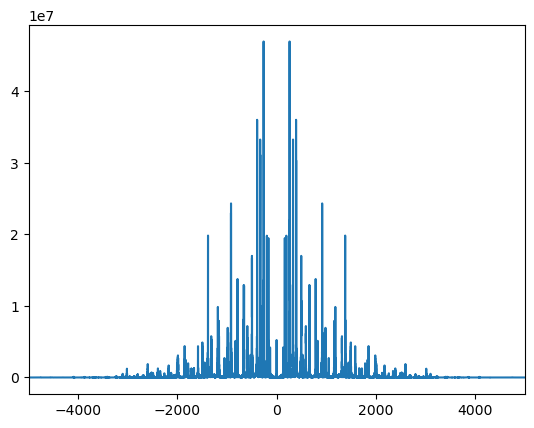

In [5]:
X = np.fft.fft(x)

freqs = fftshift(fftfreq(X.size, 1/rate))  #axedesX
print(freqs)

X=np.fft.fftshift(X)
plt.xlim(-5000,5000)
plt.plot(freqs, np.abs(X));

## Etape 2 : faire le spectrogramme ( pas facile) :(
le but c'est que pour chaque plage de temps de durée (à déterminer), on ait pr chaque fréquence un niveau d'énergie

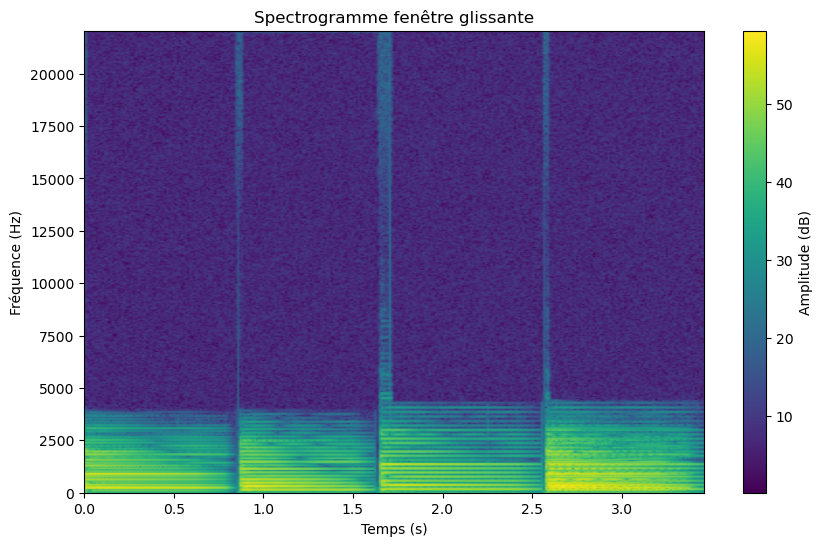

In [16]:
#Spectrogramme qui marche :)

def plot_spectrogramme(frequencies, times, spectrogram, title="Spectrogram"):

    magnitude = np.abs(spectrogram)
    plt.figure(figsize=(10, 6))
    plt.pcolormesh(times, frequencies, 10 * np.log10(magnitude+1), shading='gouraud') #20 log de magnitude = pour mettre l'amplitude en dB
    plt.colorbar(label="Amplitude (dB)")
    plt.title(title)
    plt.xlabel("Temps (s)")
    plt.ylabel("Fréquence (Hz)")
    plt.show()


def calculer_spectrogramme(x, rate, taille_fenetre, saut):

    #création d'une fenêtre de hanning
    fenetre_hann = np.hanning(taille_fenetre)

    # Nombre de fenêtres
    nb_fenetres = (x.size - taille_fenetre) // saut + 1

    # Initialisation du spectrogramme
    spectrogramme = np.zeros((taille_fenetre // 2 + 1, nb_fenetres))
    times = np.arange(nb_fenetres) * saut / rate
    frequencies = np.fft.rfftfreq(taille_fenetre, d=1/rate)

    # Calcul des TF pour chaque segment
    for i in range(nb_fenetres):
        debut = i * saut
        fin = debut + taille_fenetre
        # on prend une partie de x
        echantillon = x[debut:fin] 
        # on applique un filtre en forme de fenetre de hanning
        echantillon_filtre = echantillon * fenetre_hann
        # on applique une Real Fast Fourier Transform (car on a un signal audio, donc réel, donc on a pas besoin des complexes)
        transformee = np.fft.rfft(echantillon_filtre)
        # on l'ajoute dans une colonne du spectrogramme :)
        spectrogramme[:, i] = np.abs(transformee)

    return frequencies, times, spectrogramme

taille_fenetre = 1024  # Taille de la fenêtre (échantillons)
saut = 512  # Décalage entre fenêtres


frequences, temps, spectrogramme = calculer_spectrogramme(x, rate, taille_fenetre, saut)

plot_spectrogramme(frequences, temps, spectrogramme, title = "Spectrogramme fenêtre glissante")


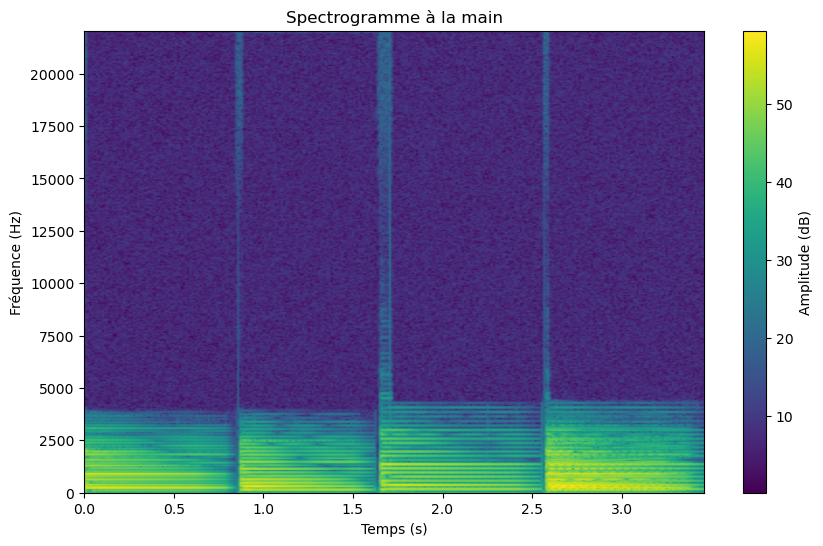

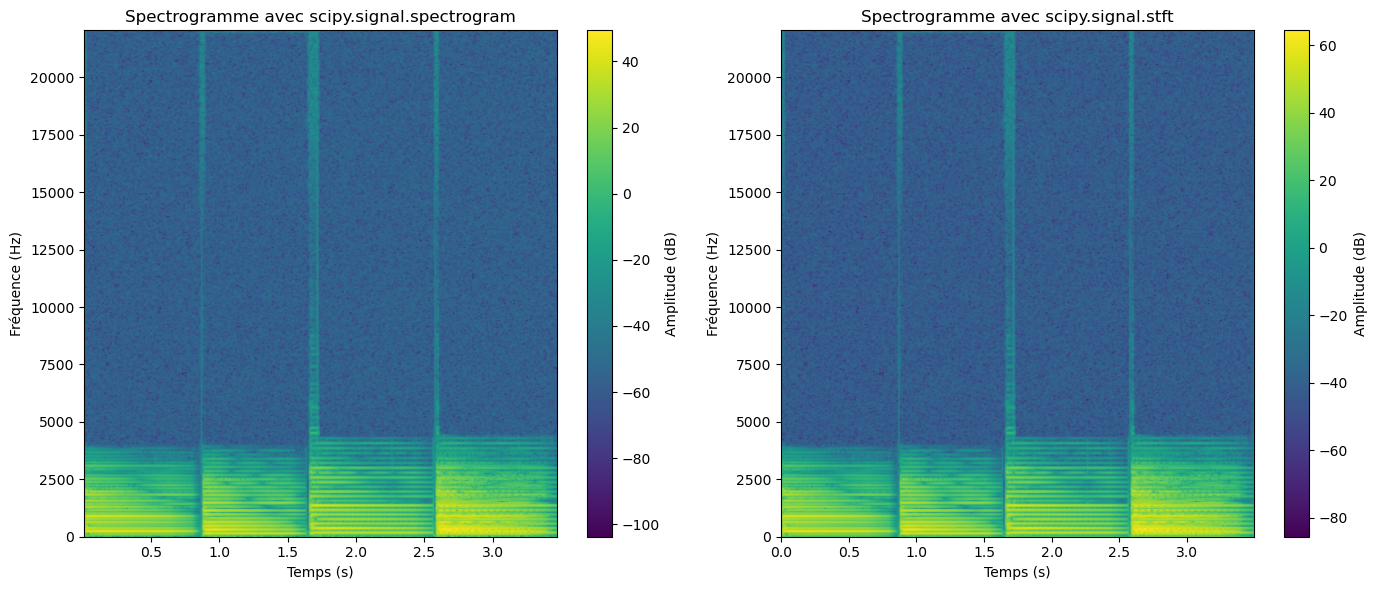

In [19]:
#Comparaison de méthodes

# Paramètres communs
taille_fenetre = 1024
saut = 512
window = "hann"

# Méthode 1 : scipy.signal.spectrogram
f1, t1, Sxx = scipy.signal.spectrogram(x, fs=rate, window=window, nperseg=taille_fenetre, noverlap=saut)

# Méthode 2 : scipy.signal.stft
f2, t2, Zxx = scipy.signal.stft(x, fs=rate, window=window, nperseg=taille_fenetre, noverlap=saut)
Sxx_stft = np.abs(Zxx)**2  # Convertir en densité spectrale de puissance

# Méthode 3 : le code à la main 
f3, t3, Sxx_a_la_main = calculer_spectrogramme(x, rate, taille_fenetre, saut)


# Affichage des trois spectrogrammes
#plot_spectrogramme(f1, t1, Sxx, title = "Spectrogramme avec signal.spectrogram")
#plot_spectrogramme(f2, t2, Sxx_stft, title = "Spectrogramme avec signal.stft")
plot_spectrogramme(f3, t3, Sxx_a_la_main, title = "Spectrogramme à la main")


plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.pcolormesh(t1, f1, 10 * np.log10(Sxx), shading='gouraud')
plt.title("Spectrogramme avec scipy.signal.spectrogram")
plt.ylabel("Fréquence (Hz)")
plt.xlabel("Temps (s)")
plt.colorbar(label="Amplitude (dB)")

plt.subplot(1, 2, 2)
plt.pcolormesh(t2, f2, 10 * np.log10(Sxx_stft), shading='gouraud')
plt.title("Spectrogramme avec scipy.signal.stft")
plt.ylabel("Fréquence (Hz)")
plt.xlabel("Temps (s)")
plt.colorbar(label="Amplitude (dB)")

plt.tight_layout()
plt.show()






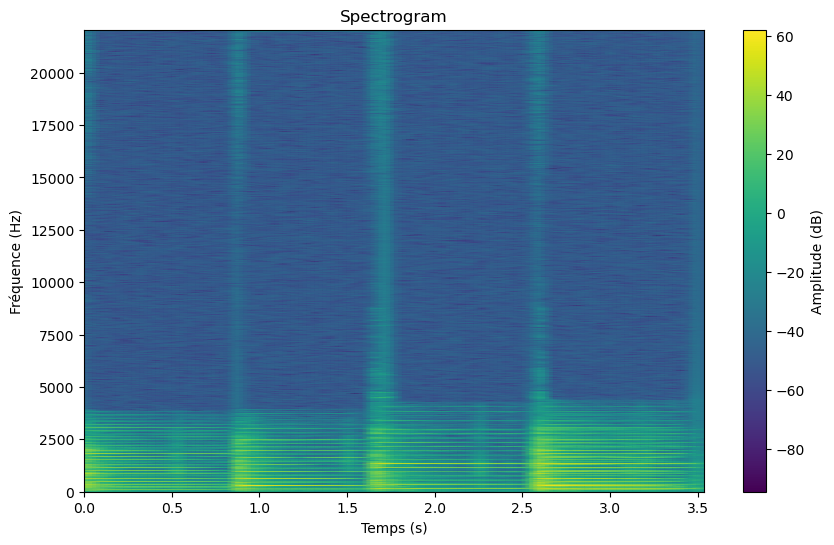

In [10]:
taille_fenetre = 6000
points_en_commun = 4000


f, t, spectrogramme = scipy.signal.stft(x, fs=rate, nperseg = taille_fenetre, noverlap = points_en_commun)
plot_spectrogramme(f, t, spectrogramme)

In [12]:
#pas besoin mais ca explique un peu 
"""
#dureeAudio = X.size / rate
nbFenetres = 4 #peut être changé
NbValeursDansPlage = math.ceil(X.size / nbFenetres)
debutPlage = 0
finPlage = debutPlage + NbValeursDansPlage
print(debutPlage, finPlage)

#on doit regarder dans la plage si il ya un signal a f=0, 1, 2 ...
#on va récupérer le signal sur la fenetre
SignalTemp = X[debutPlage:finPlage]
plt.plot(SignalTemp);
for i in range(NbValeursDansPlage):
"""
;

''

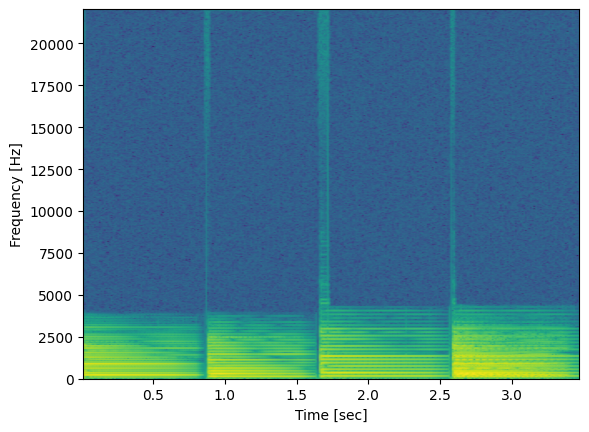

In [39]:
f, t, Sxx = signal.spectrogram(x, fs=rate, window="hann", nperseg=1024, noverlap=512)
plt.pcolormesh(t, f, 10*np.log(Sxx), shading='gouraud')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')
plt.show()

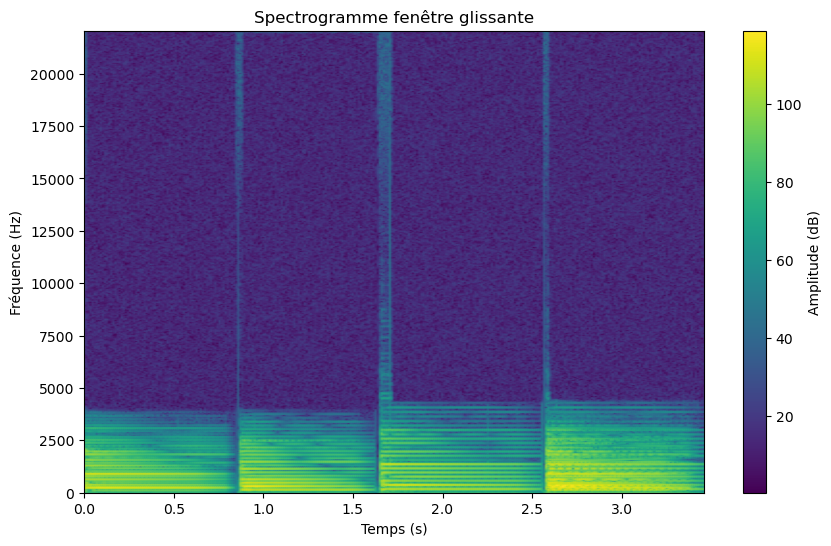